In [ ]:

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from datetime import datetime, timezone
import importlib.metadata as metadata

In [ ]:

url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

retrieval_date = datetime.now(timezone.utc).date()

print("Ticker retrieval date:", retrieval_date)
print("Total tickers:", len(tickers))


sp500_df.to_csv(
    "SP500_Ticker_List.csv",
    index=False
)


for package in ["pandas", "numpy", "yfinance"]:
    print(package, metadata.version(package))

Total tickers extracted: 503
Ticker retrieval date: 2026-11-23
Total tickers: 503
pandas 2.2.3
numpy 2.4.6
yfinance 0.2.66


In [ ]:

start = '2021-01-01'
end = '2025-01-01'

raw_data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=True
)

df = raw_data["Adj Close"]
close_prices = raw_data["Close"]
volume_data = raw_data["Volume"]

print("Adjusted prices:", df.shape)
print("Closing prices:", close_prices.shape)
print("Volume:", volume_data.shape)

raw_data.to_pickle("SP500_Daily_Raw_2021_2024.pkl")

print('Shape:', df.shape)
df.head()



[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'SNDK', 'Q', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Adjusted prices: (1005, 503)
Closing prices: (1005, 503)
Volume: (1005, 503)
Shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009109,125.537125,84.219139,139.149994,97.269684,33.186359,232.029343,485.339996,132.622681,42.189484,...,26.124496,102.852104,54.757397,33.042767,93.015884,221.160004,95.016182,141.603363,378.130005,152.952011
2021-01-05,114.941261,127.089233,85.090019,148.300003,98.473198,33.319485,233.350266,485.690002,134.993179,43.010098,...,26.371330,106.017525,54.223656,34.635185,92.903923,229.750000,95.025162,144.053436,380.570007,154.017883
2021-01-06,118.093216,122.811203,84.354958,142.770004,98.268158,34.783871,235.901627,466.309998,135.601685,44.752838,...,26.506693,106.652527,55.424545,35.518990,96.822746,226.889999,95.545944,148.158371,394.820007,156.280518
2021-01-07,121.235588,127.001907,85.257790,151.270004,99.222038,34.460564,238.127304,477.739990,141.332764,44.355209,...,26.761486,105.594185,54.340412,35.797657,101.217415,239.479996,94.818665,147.280045,409.100006,156.140244
2021-01-08,122.100464,128.098083,85.705208,149.770004,99.498398,34.650742,238.995834,485.100006,142.359055,44.473656,...,26.578348,104.901443,54.840782,36.195759,100.191063,241.449997,96.210411,146.956436,405.470001,157.178116


In [ ]:



df1 = df.T

print('Shape after transpose:', df1.shape)
df1


Shape after transpose: (503, 1005)


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009109,114.941261,118.093216,121.235588,122.100464,123.147903,122.013969,122.023582,121.110680,121.283623,...,134.353775,130.957031,131.134277,132.433899,132.522491,133.999374,133.733505,133.447968,132.345276,132.511002
AAPL,125.537125,127.089233,122.811203,127.001907,128.098083,125.119980,124.945366,126.972809,125.052086,123.335052,...,251.462646,246.075912,247.802063,252.464661,253.238419,256.145142,256.958588,253.555862,250.192841,248.427032
ABBV,84.219139,85.090019,84.354958,85.257790,85.705208,87.103378,87.710625,89.843864,90.231850,89.334625,...,164.530701,162.316696,160.909500,164.718338,167.354507,168.864899,168.114380,166.998016,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269684,98.473198,98.268158,99.222038,99.498398,98.811958,97.028992,99.979820,98.493980,99.621773,...,108.486855,107.184509,107.653740,109.387009,109.463600,109.894531,110.382896,110.114777,108.017616,108.314476
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYZ,221.160004,229.750000,226.889999,239.479996,241.449997,225.500000,227.520004,230.919998,232.789993,227.750000,...,94.550003,87.300003,87.639999,89.650002,89.290001,91.080002,91.480003,88.970001,87.480003,84.989998
YUM,95.016182,95.025162,95.545944,94.818665,96.210411,96.677322,96.677322,96.210411,96.776070,95.734512,...,130.267380,127.105705,126.042122,127.975868,129.426208,130.528458,131.495331,130.750824,129.097504,129.716263
ZBH,141.603363,144.053436,148.158371,147.280045,146.956436,147.002686,147.770081,150.654648,150.349503,148.038208,...,105.912384,103.756111,103.707108,104.991081,104.697029,105.167496,105.118484,104.746025,103.537773,103.763710


In [ ]:

benchmark_raw = yf.download(
    "^GSPC",
    start=start,
    end=end,
    auto_adjust=False,
    progress=False
)

market_prices = benchmark_raw["Adj Close"].squeeze()
market_prices.index = pd.to_datetime(market_prices.index)

market_prices = market_prices.sort_index()


trading_dates = market_prices.index


adj = df.reindex(trading_dates)
close = close_prices.reindex(trading_dates)
volume = volume_data.reindex(trading_dates)


print("Duplicate adjusted-price dates:",
      df.index.duplicated().sum())

print("Duplicate benchmark dates:",
      market_prices.index.duplicated().sum())


print("Missing adjusted prices:", adj.isna().sum().sum())
print("Missing closing prices:", close.isna().sum().sum())
print("Missing volumes:", volume.isna().sum().sum())


print("Nonpositive adjusted prices:",
      (adj <= 0).sum().sum())

print("Nonpositive closing prices:",
      (close <= 0).sum().sum())

print("Negative volumes:",
      (volume < 0).sum().sum())


valid = (
    adj.notna().all()
    & close.notna().all()
    & volume.notna().all()
    & adj.gt(0).all()
    & close.gt(0).all()
    & volume.gt(0).all()
)

valid_tickers = valid.index[valid].tolist()


exclusion_log = pd.DataFrame({
    "Share": valid.index,
    "Included": valid.values,
    "Missing_Adjusted": adj.isna().sum().values,
    "Missing_Close": close.isna().sum().values,
    "Missing_Volume": volume.isna().sum().values
})

print("Included shares:", len(valid_tickers))
print("Excluded shares:", (~valid).sum())


df1 = adj[valid_tickers].T



excluded_shares = exclusion_log[
    exclusion_log["Included"] == False
].copy()

print("Number of excluded shares:",
      len(excluded_shares))

display(excluded_shares)



exclusion_details = pd.DataFrame({
    "Share": valid.index,
    "Missing_Prices": adj.isna().sum().values,
    "Missing_Volumes": volume.isna().sum().values,
    "Nonpositive_Prices": (
        (adj <= 0) | (close <= 0)
    ).sum().values,
    "Zero_Volumes": (volume == 0).sum().values
})

display(
    exclusion_details[
        exclusion_details["Share"].isin(
            excluded_shares["Share"]
        )
    ]
)



Duplicate adjusted-price dates: 0
Duplicate benchmark dates: 0
Missing adjusted prices: 9211
Missing closing prices: 9211
Missing volumes: 9211
Nonpositive adjusted prices: 0
Nonpositive closing prices: 0
Negative volumes: 0
Included shares: 486
Excluded shares: 17
Number of excluded shares: 17


,Share,Included,Missing_Adjusted,Missing_Close,Missing_Volume
39,APP,False,70,70,70
84,CEG,False,263,263,263
104,COIN,False,69,69,69
171,EXE,False,26,26,26
181,FDXF,False,1005,1005,1005
183,FERG,False,0,0,0
200,GEHC,False,492,492,492
202,GEV,False,812,812,812
225,HONA,False,1005,1005,1005
226,HOOD,False,143,143,143


,Share,Missing_Prices,Missing_Volumes,Nonpositive_Prices,Zero_Volumes
39,APP,70,70,0,0
84,CEG,263,263,0,0
104,COIN,69,69,0,0
171,EXE,26,26,0,0
181,FDXF,1005,1005,0,0
183,FERG,0,0,0,27
200,GEHC,492,492,0,0
202,GEV,812,812,0,0
225,HONA,1005,1005,0,0
226,HOOD,143,143,0,0


In [ ]:
import pandas as pd




def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from adjusted closing prices."""


    prices = df1 if shares is None else df1.loc[shares]


    prices = prices.T.copy()


    prices.index = pd.to_datetime(prices.index)


    prices = prices.sort_index()


    weekly_prices = prices.resample("W-FRI").last()


    week_start = weekly_prices.index - pd.Timedelta(days=4)

    complete_weeks = (
        (week_start >= pd.Timestamp(start))
        & (weekly_prices.index < pd.Timestamp(end))
    )

    weekly_prices = weekly_prices.loc[complete_weeks]


    weekly_returns = weekly_prices.pct_change(fill_method=None)

    return weekly_returns


In [ ]:

weekly_returns = calculate_weekly_returns(df1)
mean_weekly_return = weekly_returns.mean()

weekly_counts = weekly_returns.count()

print("Mean weekly returns:")
print(mean_weekly_return.head())

print("Weekly observation counts:")
print(weekly_counts.head())

Mean weekly returns:
Ticker
A       0.001121
AAPL    0.003930
ABBV    0.003749
ABNB    0.001475
ABT     0.000971
dtype: float64
Weekly observation counts:
Ticker
A       207
AAPL    207
ABBV    207
ABNB    207
ABT     207
dtype: int64


In [ ]:
weekly_returns


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012166,0.053454,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038963
2021-01-22,0.000951,0.093833,0.003077,0.074437,0.013837,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.021218,0.011485,-0.003079,-0.009606,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095267,-0.057040,-0.050438,-0.028935,-0.053027,-0.053199,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048033,0.072694,0.009706,0.065786,...,0.102918,0.175425,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040477,0.049713,0.032609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.030858,0.032453,0.033795,-0.008956,0.008577,0.010332,0.010344,0.007381,0.016124,0.027668,...,0.039074,0.033848,0.016959,-0.031448,0.001851,-0.040212,0.027131,0.017057,0.024699,-0.009663
2024-12-06,0.018917,0.023216,-0.036845,0.005951,-0.026690,-0.028693,0.000911,0.071773,0.000688,-0.058242,...,-0.030068,-0.000106,-0.038865,-0.037216,-0.002998,0.109543,-0.004629,-0.036307,0.005700,0.006904
2024-12-13,-0.011239,0.021784,-0.016005,-0.043602,-0.019204,-0.045078,-0.011084,-0.157823,-0.003083,0.019059,...,-0.039310,0.001695,-0.023229,-0.024038,-0.045660,-0.063817,-0.004577,-0.011941,-0.013999,0.009747


In [ ]:
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [ ]:



market_weekly_prices = market_prices.resample("W-FRI").last()

week_start = market_weekly_prices.index - pd.Timedelta(days=4)

complete_weeks = (
    (week_start >= pd.Timestamp(start))
    & (market_weekly_prices.index < pd.Timestamp(end))
)

market_weekly_prices = market_weekly_prices.loc[complete_weeks]

market_weekly_returns = market_weekly_prices.pct_change(
    fill_method=None
)


beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns
)

print(beta_df.head())


           Beta  Paired_weeks
Share                        
A      1.074724           207
AAPL   1.174835           207
ABBV   0.425365           207
ABNB   1.472709           207
ABT    0.583543           207


In [ ]:

combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

,Week,Share,Weekly_Return,Beta
0,2021-01-08,A,NaN,1.074724
1,2021-01-15,A,-0.006690,1.074724
2,2021-01-22,A,0.000951,1.074724
3,2021-01-29,A,-0.048761,1.074724
4,2021-02-05,A,0.025048,1.074724
...,...,...,...,...
101083,2024-11-29,ZTS,-0.009663,0.979782
101084,2024-12-06,ZTS,0.006904,0.979782
101085,2024-12-13,ZTS,0.009747,0.979782
101086,2024-12-20,ZTS,-0.074868,0.979782


In [ ]:

print("Null values per column:")
print(combined_df.isna().sum())


rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))

Null values per column:
Week               0
Share              0
Weekly_Return    486
Beta               0
dtype: int64
Rows removed: 486
Rows remaining: 100602


In [ ]:


import pandas as pd
import numpy as np


observation_date = trading_dates.max()
last60_dates = trading_dates[-60:]

print("Observation date:", observation_date.date())
print("Start of 60 sessions:", last60_dates[0].date())

results = []

for share in valid_tickers:


    daily = pd.DataFrame({
        "Close": close[share],
        "Volume": volume[share]
    }).sort_index()


    daily["Previous20Mean"] = (
        daily["Volume"]
        .shift(1)
        .rolling(20, min_periods=20)
        .mean()
    )


    daily["HighVolume"] = (
        (daily["Volume"] > 2 * daily["Previous20Mean"])
        & daily["Previous20Mean"].notna()
    )


    event_dates = daily.index[daily["HighVolume"]]

    if len(event_dates) > 0:
        last_event = event_dates[-1]
        R = (observation_date - last_event).days
    else:
        last_event = pd.NaT
        R = np.nan


    last60 = daily.loc[last60_dates].copy()


    if len(last60) != 60:
        raise ValueError(f"Incomplete window: {share}")

    if last60["Previous20Mean"].isna().any():
        raise ValueError(f"Insufficient baseline: {share}")


    F = int(last60["HighVolume"].sum())


    M = (
        last60["Close"] * last60["Volume"]
    ).sum()

    results.append({
        "Share": share,
        "Recency": R,
        "Frequency": F,
        "Monetary": M,
        "Last_Event": last_event
    })


rfm = pd.DataFrame(results)

print("Number of shares:", len(rfm))
print("Shares with missing Recency:",
      rfm["Recency"].isna().sum())

display(rfm.head(10))



Observation date: 2024-12-31
Start of 60 sessions: 2024-10-07
Number of shares: 486
Shares with missing Recency: 0


,Share,Recency,Frequency,Monetary,Last_Event
0,A,11,2,1.400180e+10,2024-12-20
1,AAPL,11,2,6.233034e+11,2024-12-20
2,ABBV,11,3,6.837054e+10,2024-12-20
3,ABNB,11,3,3.652850e+10,2024-12-20
4,ABT,11,1,3.523027e+10,2024-12-20
5,ACGL,11,4,1.196213e+10,2024-12-20
6,ACN,11,2,5.199430e+10,2024-12-20
7,ADBE,18,3,1.030403e+11,2024-12-13
8,ADI,36,1,3.849918e+10,2024-11-25
9,ADM,11,3,9.529780e+09,2024-12-20


In [ ]:


returns_table = (
    mean_weekly_return
    .rename("Mean_Weekly_Return")
    .rename_axis("Share")
    .reset_index()
)


beta_table = beta_df.reset_index()


features = (
    returns_table
    .merge(beta_table, on="Share")
    .merge(rfm, on="Share")
)


features = features[[
    "Share",
    "Mean_Weekly_Return",
    "Beta",
    "Paired_weeks",
    "Recency",
    "Frequency",
    "Monetary",
    "Last_Event"
]]


print("Total shares:", len(features))
print("Duplicate shares:",
      features["Share"].duplicated().sum())

print("Missing values:")
print(features.isna().sum())

print("Feature summary:")
display(features.describe())

print("First 10 shares:")
display(features.head(10))


features.to_csv(
    "SP500_Task1_Features.csv",
    index=False
)

exclusion_log.to_csv(
    "SP500_Exclusion_Log.csv",
    index=False
)


clustering_features = features.dropna(
    subset=[
        "Mean_Weekly_Return",
        "Beta",
        "Recency",
        "Frequency",
        "Monetary"
    ]
).copy()

clustering_features.to_csv(
    "SP500_Clustering_Features.csv",
    index=False
)

print("Shares available for clustering:",
      len(clustering_features))



Total shares: 486
Duplicate shares: 0
Missing values:
Share                 0
Mean_Weekly_Return    0
Beta                  0
Paired_weeks          0
Recency               0
Frequency             0
Monetary              0
Last_Event            0
dtype: int64
Feature summary:


,Mean_Weekly_Return,Beta,Paired_weeks,Recency,Frequency,Monetary,Last_Event
count,486.000000,486.000000,486.0,486.000000,486.000000,4.860000e+02,486
mean,0.002857,0.973695,207.0,20.407407,2.989712,3.940419e+10,2024-12-10 14:13:20
min,-0.004468,0.055453,207.0,4.000000,0.000000,1.297483e+09,2024-05-23 00:00:00
25%,0.001182,0.666600,207.0,11.000000,2.000000,1.019517e+10,2024-12-16 06:00:00
50%,0.002619,0.950611,207.0,11.000000,3.000000,1.668382e+10,2024-12-20 00:00:00
75%,0.004207,1.179538,207.0,14.750000,4.000000,3.227689e+10,2024-12-20 00:00:00
max,0.017772,3.778560,207.0,222.000000,8.000000,1.847697e+12,2024-12-27 00:00:00
std,0.002652,0.407339,0.0,21.342438,1.330800,1.291388e+11,NaN


First 10 shares:


,Share,Mean_Weekly_Return,Beta,Paired_weeks,Recency,Frequency,Monetary,Last_Event
0,A,0.001121,1.074724,207,11,2,1.400180e+10,2024-12-20
1,AAPL,0.003930,1.174835,207,11,2,6.233034e+11,2024-12-20
2,ABBV,0.003749,0.425365,207,11,3,6.837054e+10,2024-12-20
3,ABNB,0.001475,1.472709,207,11,3,3.652850e+10,2024-12-20
4,ABT,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-20
5,ACGL,0.005289,0.586638,207,11,4,1.196213e+10,2024-12-20
6,ACN,0.002376,1.143300,207,11,2,5.199430e+10,2024-12-20
7,ADBE,0.000990,1.553525,207,18,3,1.030403e+11,2024-12-13
8,ADI,0.002610,1.131968,207,36,1,3.849918e+10,2024-11-25
9,ADM,0.001048,0.548877,207,11,3,9.529780e+09,2024-12-20


Shares available for clustering: 486


In [ ]:



share = "AAPL"

daily_example = pd.DataFrame({
    "Close": close[share],
    "Volume": volume[share]
}).sort_index()

daily_example["Previous20Mean"] = (
    daily_example["Volume"]
    .shift(1)
    .rolling(20, min_periods=20)
    .mean()
)

daily_example["Threshold"] = (
    2 * daily_example["Previous20Mean"]
)

daily_example["HighVolume"] = (
    daily_example["Volume"] >
    daily_example["Threshold"]
)

daily_example["TradedValue"] = (
    daily_example["Close"] *
    daily_example["Volume"]
)

print("AAPL - final 60 trading sessions")
display(daily_example.loc[last60_dates].tail(10))

print("AAPL calculated features")
display(rfm[rfm["Share"] == share])


print("Frequency check:",
    daily_example.loc[last60_dates, "HighVolume"].sum())


print("Monetary check:",
    daily_example.loc[last60_dates, "TradedValue"].sum())


AAPL - final 60 trading sessions


,Close,Volume,Previous20Mean,Threshold,HighVolume,TradedValue
Date,,,,,,
2024-12-17,253.479996,51356400,42354720.0,84709440.0,False,1.301782e+10
2024-12-18,248.050003,56774100,42690855.0,85381710.0,False,1.408282e+10
2024-12-19,249.789993,60882300,43718970.0,87437940.0,False,1.520779e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10
2024-12-23,255.270004,40858800,50273955.0,100547910.0,False,1.043003e+10
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False,8.967601e+09


AAPL calculated features


,Share,Recency,Frequency,Monetary,Last_Event
1,AAPL,11,2,6.233034e+11,2024-12-20


Frequency check: 2
Monetary check: 623303377706.5842


In [ ]:



print("Observation date:", observation_date.date())
print("Trading sessions in window:", len(last60_dates))

print("Final feature table:")
display(features.head())

print("Feature summary:")
display(features[[
    "Mean_Weekly_Return",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]].describe())

print("Aligned weekly observations:")
display(features["Paired_weeks"].describe())

print("Missing values:")
display(features.isna().sum())

print("Excluded shares:")
display(exclusion_log[
    exclusion_log["Included"] == False
])



print("Available data fields:")
print(raw_data.columns.get_level_values(0).unique())

for field in ["Stock Splits", "Dividends"]:
    if field in raw_data.columns.get_level_values(0):

        actions = raw_data[field]
        nonzero = actions.fillna(0).ne(0).sum()

        print(f"\n{field} - shares with events:")
        display(nonzero[nonzero > 0].head(20))


Observation date: 2024-12-31
Trading sessions in window: 60
Final feature table:


,Share,Mean_Weekly_Return,Beta,Paired_weeks,Recency,Frequency,Monetary,Last_Event
0,A,0.001121,1.074724,207,11,2,1.400180e+10,2024-12-20
1,AAPL,0.003930,1.174835,207,11,2,6.233034e+11,2024-12-20
2,ABBV,0.003749,0.425365,207,11,3,6.837054e+10,2024-12-20
3,ABNB,0.001475,1.472709,207,11,3,3.652850e+10,2024-12-20
4,ABT,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-20


Feature summary:


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055453,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666600,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950611,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


Aligned weekly observations:


,Paired_weeks
count,486.0
mean,207.0
std,0.0
min,207.0
25%,207.0
50%,207.0
75%,207.0
max,207.0


... (4 outputs left out)

Available data fields:
Index(['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open',
       'Stock Splits', 'Volume'],
      dtype='object', name='Price')

Stock Splits - shares with events:


,0
Ticker,
AMZN,1
ANET,2
APH,2
AVGO,1
BDX,1
CMG,1
COO,1
CPRT,2
CSGP,1



Dividends - shares with events:


,0
Ticker,
A,17
AAPL,16
ABBV,16
ABT,16
ACGL,1
ACN,16
ADI,16
ADM,16
ADP,16


In [ ]:



import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


task2_data = clustering_features.copy()


task2_data = task2_data.replace(
    [np.inf, -np.inf], np.nan
)

required_features = [
    "Mean_Weekly_Return",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]

task2_data = task2_data.dropna(
    subset=required_features
).copy()


assert (task2_data["Monetary"] >= 0).all()

print("Number of shares:", len(task2_data))


risk_return_features = task2_data[[
    "Mean_Weekly_Return",
    "Beta"
]].copy()


rfm_features = task2_data[[
    "Recency",
    "Frequency",
    "Monetary"
]].copy()


rfm_features["Log_Monetary"] = np.log1p(
    rfm_features["Monetary"]
)


rfm_input = rfm_features[[
    "Recency",
    "Frequency",
    "Log_Monetary"
]]


risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

X_risk = risk_scaler.fit_transform(
    risk_return_features
)

X_rfm = rfm_scaler.fit_transform(
    rfm_input
)

print("Risk and return shape:", X_risk.shape)
print("RFM shape:", X_rfm.shape)

display(risk_return_features.head())
display(rfm_input.head())


Number of shares: 486
Risk and return shape: (486, 2)
RFM shape: (486, 3)


,Mean_Weekly_Return,Beta
0,0.001121,1.074724
1,0.003930,1.174835
2,0.003749,0.425365
3,0.001475,1.472709
4,0.000971,0.583543


,Recency,Frequency,Log_Monetary
0,11,2,23.362451
1,11,2,27.158299
2,11,3,24.948208
3,11,3,24.321359
4,11,1,24.285172


Original feature skewness:


,Skewness
Mean_Weekly_Return,0.867516
Beta,1.103649
Recency,3.645784
Frequency,0.424735
Monetary,11.683797


,Feature,Skewness
0,Monetary,11.683797
1,Log_Monetary,1.079057


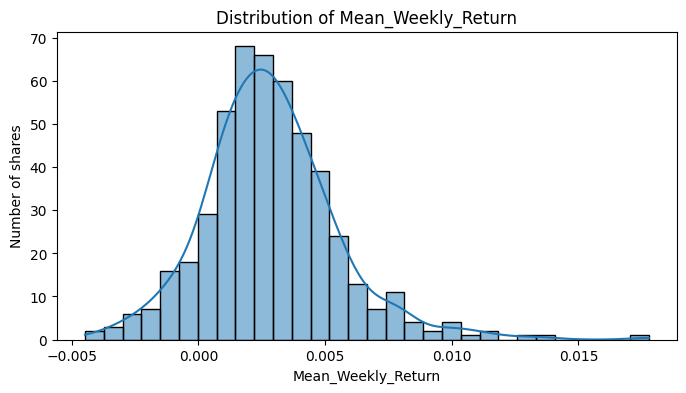

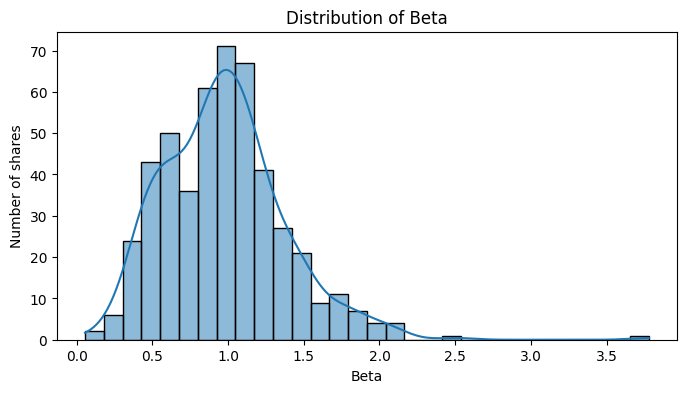

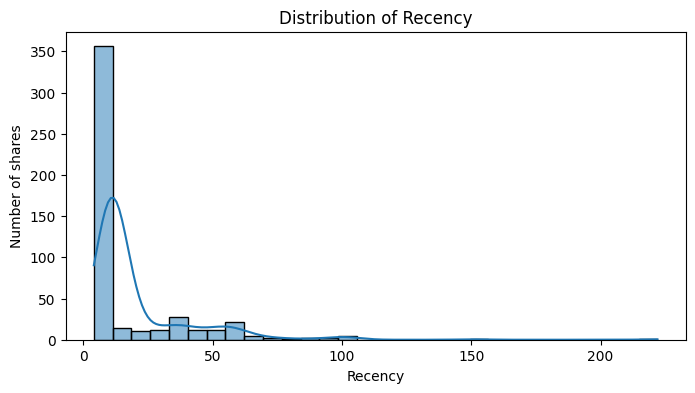

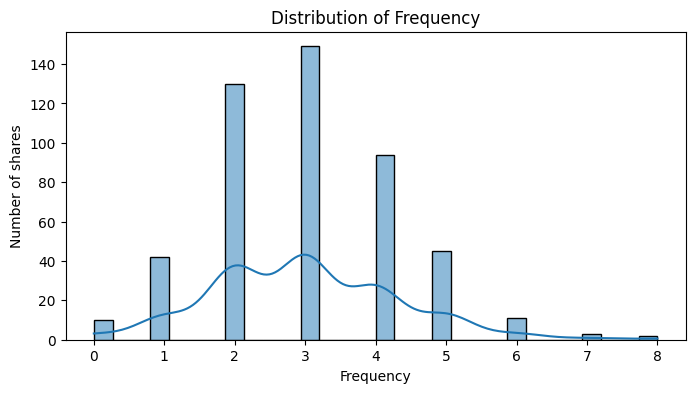

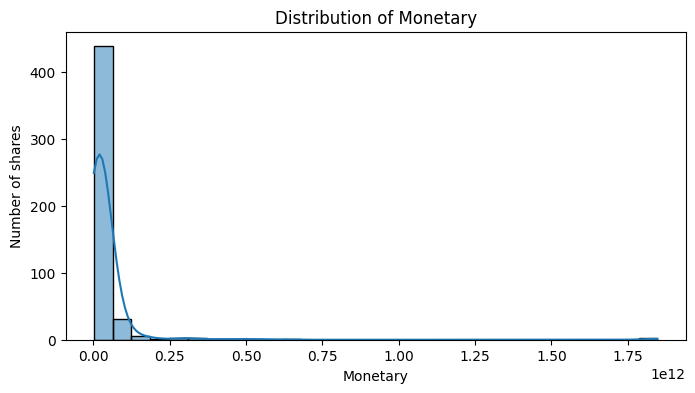

Outliers detected by feature:


,Outlier_Count
Mean_Weekly_Return,15
Beta,10
Recency,115
Frequency,2
Monetary,45


In [ ]:



import matplotlib.pyplot as plt
import seaborn as sns

feature_columns = [
    "Mean_Weekly_Return",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]


print("Original feature skewness:")
display(
    task2_data[feature_columns]
    .skew()
    .to_frame("Skewness")
)


skew_comparison = pd.DataFrame({
    "Feature": ["Monetary", "Log_Monetary"],
    "Skewness": [
        task2_data["Monetary"].skew(),
        rfm_input["Log_Monetary"].skew()
    ]
})

display(skew_comparison)


for column in feature_columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(
        task2_data[column],
        bins=30,
        kde=True
    )
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of shares")
    plt.show()


Q1 = task2_data[feature_columns].quantile(0.25)
Q3 = task2_data[feature_columns].quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (task2_data[feature_columns] < Q1 - 1.5 * IQR)
    |
    (task2_data[feature_columns] > Q3 + 1.5 * IQR)
)

print("Outliers detected by feature:")
display(outliers.sum().to_frame("Outlier_Count"))


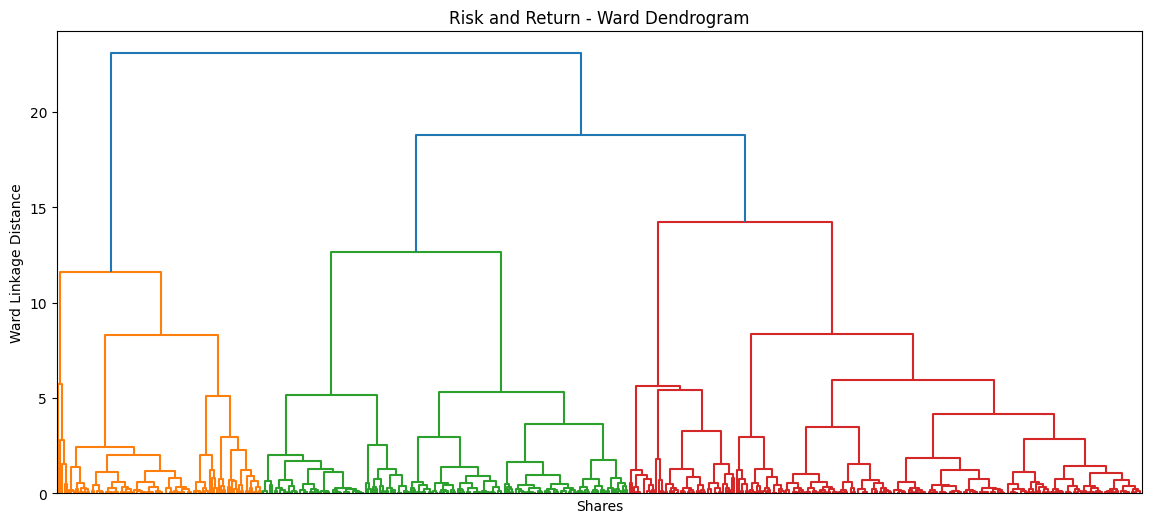

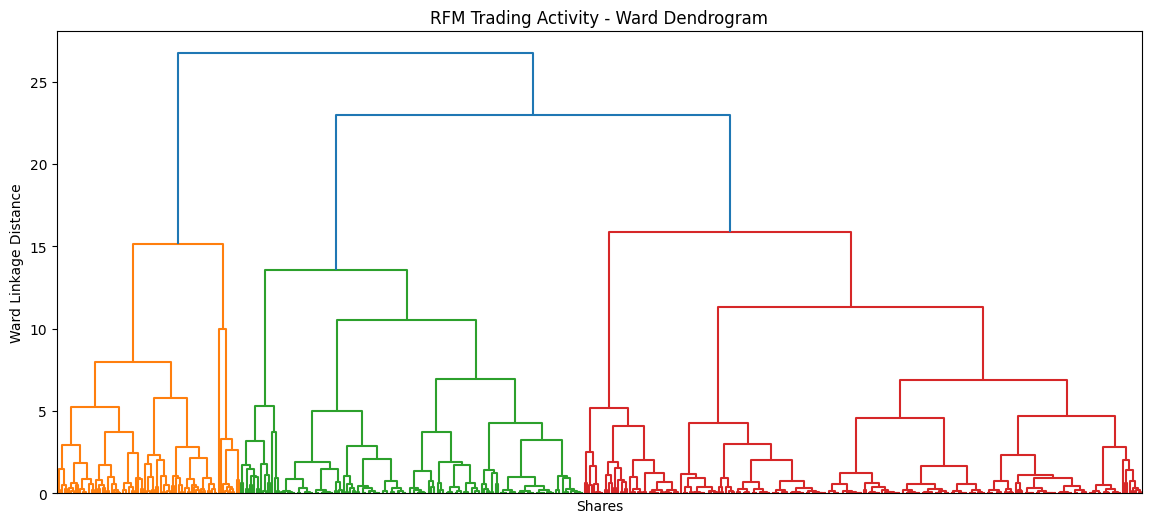

In [ ]:



from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt


ward_risk = linkage(
    X_risk,
    method="ward",
    metric="euclidean"
)


ward_rfm = linkage(
    X_rfm,
    method="ward",
    metric="euclidean"
)


plt.figure(figsize=(14, 6))
dendrogram(
    ward_risk,
    no_labels=True
)
plt.title("Risk and Return - Ward Dendrogram")
plt.xlabel("Shares")
plt.ylabel("Ward Linkage Distance")
plt.show()


plt.figure(figsize=(14, 6))
dendrogram(
    ward_rfm,
    no_labels=True
)
plt.title("RFM Trading Activity - Ward Dendrogram")
plt.xlabel("Shares")
plt.ylabel("Ward Linkage Distance")
plt.show()


Ward clustering comparison:


,Dataset,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk_Return,2,0.339485,92,394,"[394, 92]"
1,Risk_Return,3,0.273834,92,230,"[230, 92, 164]"
2,Risk_Return,4,0.282115,48,182,"[164, 92, 182, 48]"
3,Risk_Return,5,0.304135,48,182,"[92, 48, 182, 98, 66]"
4,Risk_Return,6,0.320409,5,182,"[182, 48, 87, 98, 66, 5]"
5,Risk_Return,7,0.323951,5,160,"[87, 48, 160, 98, 66, 5, 22]"
6,Risk_Return,8,0.320779,5,160,"[160, 48, 5, 98, 66, 31, 22, 56]"
7,RFM,2,0.368024,82,404,"[404, 82]"
8,RFM,3,0.303979,82,250,"[250, 82, 154]"
9,RFM,4,0.288765,43,207,"[82, 207, 154, 43]"


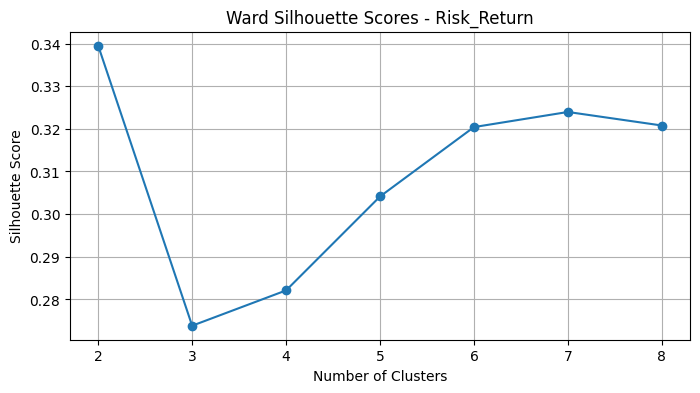

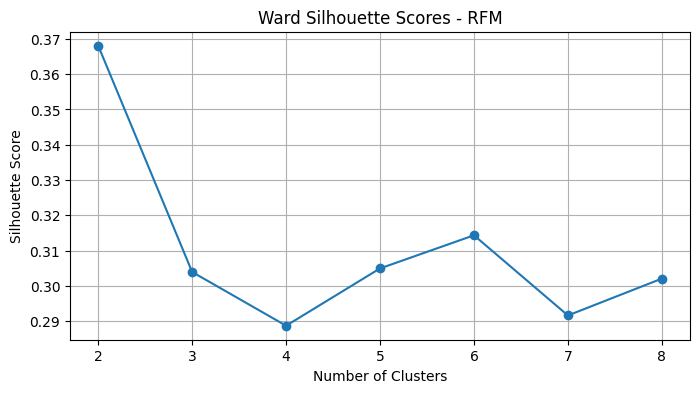

In [ ]:



from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

ward_results = []

for name, X in [
    ("Risk_Return", X_risk),
    ("RFM", X_rfm)
]:
    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        score = silhouette_score(X, labels)

        sizes = pd.Series(labels).value_counts().sort_index()

        ward_results.append({
            "Dataset": name,
            "Clusters": k,
            "Silhouette": score,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": sizes.tolist()
        })

ward_comparison = pd.DataFrame(ward_results)

print("Ward clustering comparison:")
display(ward_comparison)


for name in ["Risk_Return", "RFM"]:

    subset = ward_comparison[
        ward_comparison["Dataset"] == name
    ]

    plt.figure(figsize=(8, 4))

    plt.plot(
        subset["Clusters"],
        subset["Silhouette"],
        marker="o"
    )

    plt.title(f"Ward Silhouette Scores - {name}")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Silhouette Score")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.show()


In [ ]:



from sklearn.cluster import AgglomerativeClustering

profile_columns = [
    "Mean_Weekly_Return",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]

for dataset_name, X in [
    ("Risk_Return", X_risk),
    ("RFM", X_rfm)
]:
    for k in [2, 3]:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        comparison = task2_data.copy()
        comparison["Cluster"] = labels + 1

        print(f"\n{dataset_name} - {k} clusters")

        print("Cluster sizes:")
        display(
            comparison["Cluster"]
            .value_counts()
            .sort_index()
        )


        print("Cluster profiles:")
        display(
            comparison.groupby("Cluster")[
                profile_columns
            ].mean().round(4)
        )



Risk_Return - 2 clusters
Cluster sizes:


,count
Cluster,
1,394
2,92


Cluster profiles:


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
Cluster,,,,,
1,0.0020,0.8979,19.6447,2.9416,3.020963e+10
2,0.0063,1.2981,23.6739,3.1957,7.878092e+10



Risk_Return - 3 clusters
Cluster sizes:


,count
Cluster,
1,230
2,92
3,164


... (6 outputs left out)


RFM - 3 clusters
Cluster sizes:


,count
Cluster,
1,250
2,82
3,154


Cluster profiles:


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
Cluster,,,,,
1,0.0025,0.9400,12.1200,3.3600,1.176413e+10
2,0.0029,1.0089,58.3049,2.0976,4.715898e+10
3,0.0034,1.0096,13.6818,2.8636,8.014525e+10


K-means clustering comparison:


,Dataset,Clusters,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk_Return,2,0.386950,621.634398,143,343,"[143, 343]"
1,Risk_Return,3,0.328907,461.178714,119,202,"[119, 202, 165]"
2,Risk_Return,4,0.326103,371.571224,41,160,"[160, 41, 132, 153]"
3,Risk_Return,5,0.338131,309.959938,28,165,"[165, 114, 28, 124, 55]"
4,Risk_Return,6,0.327262,265.852156,16,137,"[55, 137, 119, 81, 16, 78]"
5,Risk_Return,7,0.329204,227.238585,5,126,"[78, 47, 5, 84, 105, 126, 41]"
6,Risk_Return,8,0.355782,194.595920,5,141,"[29, 141, 81, 77, 31, 43, 79, 5]"
7,RFM,2,0.423122,1066.831882,68,418,"[418, 68]"
8,RFM,3,0.324976,796.614361,64,270,"[270, 64, 152]"
9,RFM,4,0.340867,609.832467,61,212,"[212, 122, 61, 91]"


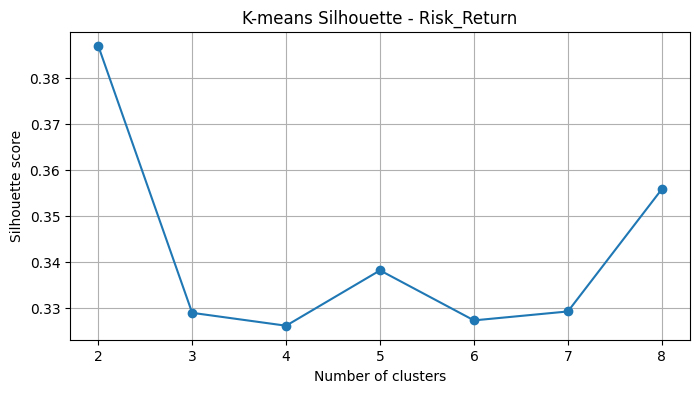

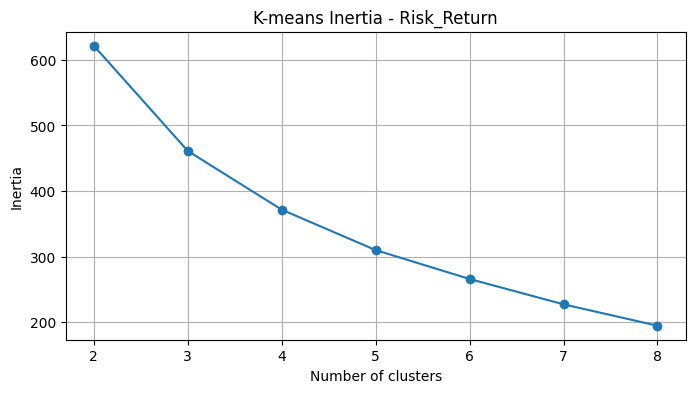

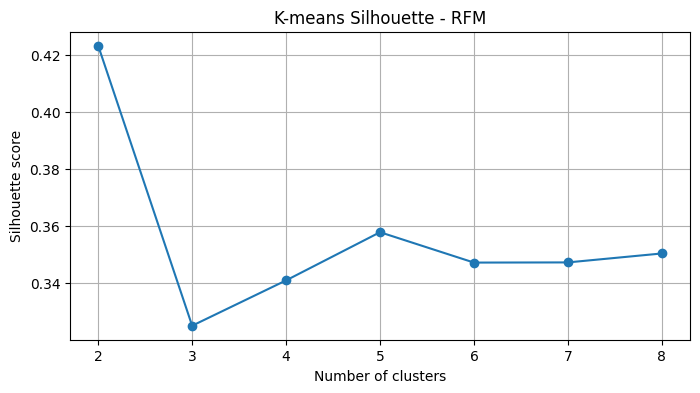

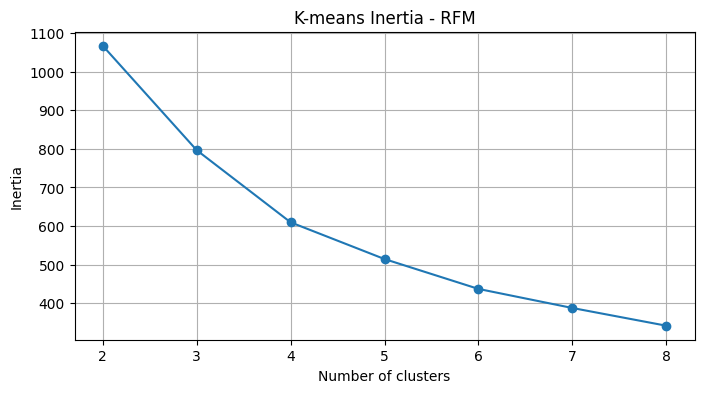

In [ ]:



from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

kmeans_results = []

for dataset_name, X in [
    ("Risk_Return", X_risk),
    ("RFM", X_rfm)
]:
    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X)

        silhouette = silhouette_score(X, labels)

        sizes = pd.Series(labels).value_counts().sort_index()

        kmeans_results.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Silhouette": silhouette,
            "Inertia": model.inertia_,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": sizes.tolist()
        })

kmeans_comparison = pd.DataFrame(kmeans_results)

print("K-means clustering comparison:")
display(kmeans_comparison)


for dataset_name in ["Risk_Return", "RFM"]:

    subset = kmeans_comparison[
        kmeans_comparison["Dataset"] == dataset_name
    ]

    plt.figure(figsize=(8, 4))
    plt.plot(
        subset["Clusters"],
        subset["Silhouette"],
        marker="o"
    )
    plt.title(f"K-means Silhouette - {dataset_name}")
    plt.xlabel("Number of clusters")
    plt.ylabel("Silhouette score")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(
        subset["Clusters"],
        subset["Inertia"],
        marker="o"
    )
    plt.title(f"K-means Inertia - {dataset_name}")
    plt.xlabel("Number of clusters")
    plt.ylabel("Inertia")
    plt.xticks(range(2, 9))
    plt.grid(True)
    plt.show()


In [ ]:



from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd


k_risk = 2
k_rfm = 2


ward_risk_labels = AgglomerativeClustering(
    n_clusters=k_risk, linkage="ward"
).fit_predict(X_risk)

ward_rfm_labels = AgglomerativeClustering(
    n_clusters=k_rfm, linkage="ward"
).fit_predict(X_rfm)


km_risk_labels = KMeans(
    n_clusters=k_risk,
    random_state=42,
    n_init=20
).fit_predict(X_risk)

km_rfm_labels = KMeans(
    n_clusters=k_rfm,
    random_state=42,
    n_init=20
).fit_predict(X_rfm)


cluster_results = task2_data.copy()

cluster_results["Ward_Risk"] = ward_risk_labels + 1
cluster_results["Ward_RFM"] = ward_rfm_labels + 1
cluster_results["KMeans_Risk"] = km_risk_labels + 1
cluster_results["KMeans_RFM"] = km_rfm_labels + 1


columns = [
    "Mean_Weekly_Return",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]

for method in [
    "Ward_Risk", "KMeans_Risk",
    "Ward_RFM", "KMeans_RFM"
]:
    print(f"\nCluster profiles: {method}")

    profiles = cluster_results.groupby(
        method
    )[columns].mean()

    profiles["Mean_Weekly_Return"] *= 100
    profiles["Monetary"] /= 1e9

    profiles = profiles.rename(columns={
        "Mean_Weekly_Return": "Return_%",
        "Monetary": "Monetary_USD_Billions"
    })

    display(profiles.round(3))


print("Ward vs K-means - Risk/Return:")
print(adjusted_rand_score(
    ward_risk_labels, km_risk_labels
))

print("Ward vs K-means - RFM:")
print(adjusted_rand_score(
    ward_rfm_labels, km_rfm_labels
))

cluster_results.to_csv(
    "SP500_Task2_Cluster_Assignments.csv",
    index=False
)



Cluster profiles: Ward_Risk


,Return_%,Beta,Recency,Frequency,Monetary_USD_Billions
Ward_Risk,,,,,
1,0.205,0.898,19.645,2.942,30.210
2,0.632,1.298,23.674,3.196,78.781



Cluster profiles: KMeans_Risk


,Return_%,Beta,Recency,Frequency,Monetary_USD_Billions
KMeans_Risk,,,,,
1,0.533,1.350,22.636,3.147,81.438
2,0.183,0.817,19.478,2.924,21.880



Cluster profiles: Ward_RFM


,Return_%,Beta,Recency,Frequency,Monetary_USD_Billions
Ward_RFM,,,,,
1,0.286,0.967,12.715,3.171,37.830
2,0.286,1.009,58.305,2.098,47.159



Cluster profiles: KMeans_RFM


,Return_%,Beta,Recency,Frequency,Monetary_USD_Billions
KMeans_RFM,,,,,
1,0.283,0.972,13.423,3.187,32.691
2,0.302,0.982,63.338,1.779,80.671


Ward vs K-means - Risk/Return:
0.59755503175211
Ward vs K-means - RFM:
0.6998191613914165


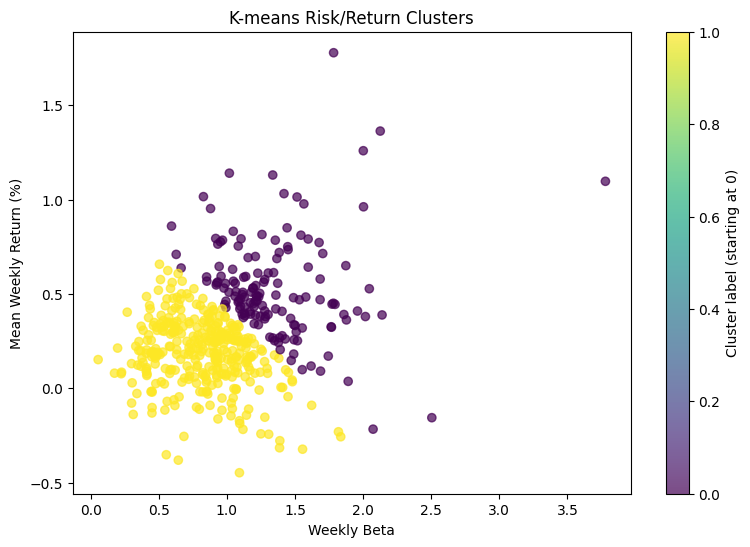

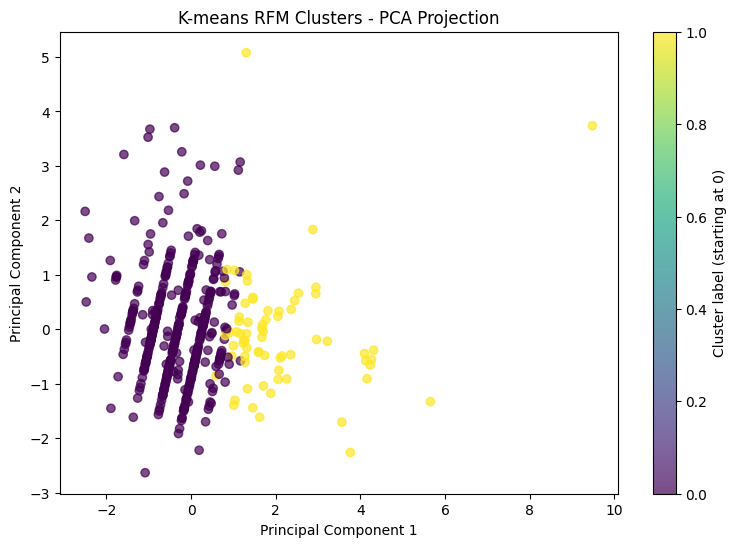

PCA explained variance ratios:
[0.45793575 0.33647299]
Total variance represented:
0.7944087363610063


In [ ]:



import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


plt.figure(figsize=(9, 6))
plt.scatter(
    task2_data["Beta"],
    task2_data["Mean_Weekly_Return"] * 100,
    c=km_risk_labels,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel("Weekly Beta")
plt.ylabel("Mean Weekly Return (%)")
plt.title("K-means Risk/Return Clusters")
plt.colorbar(label="Cluster label (starting at 0)")
plt.show()


pca = PCA(n_components=2)
X_rfm_2d = pca.fit_transform(X_rfm)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_rfm_2d[:, 0],
    X_rfm_2d[:, 1],
    c=km_rfm_labels,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-means RFM Clusters - PCA Projection")
plt.colorbar(label="Cluster label (starting at 0)")
plt.show()

print("PCA explained variance ratios:")
print(pca.explained_variance_ratio_)

print("Total variance represented:")
print(pca.explained_variance_ratio_.sum())


RFM feature correlations:


,Recency,Frequency,Log_Monetary
Recency,1.0000,-0.3463,0.1524
Frequency,-0.3463,1.0000,0.0128
Log_Monetary,0.1524,0.0128,1.0000


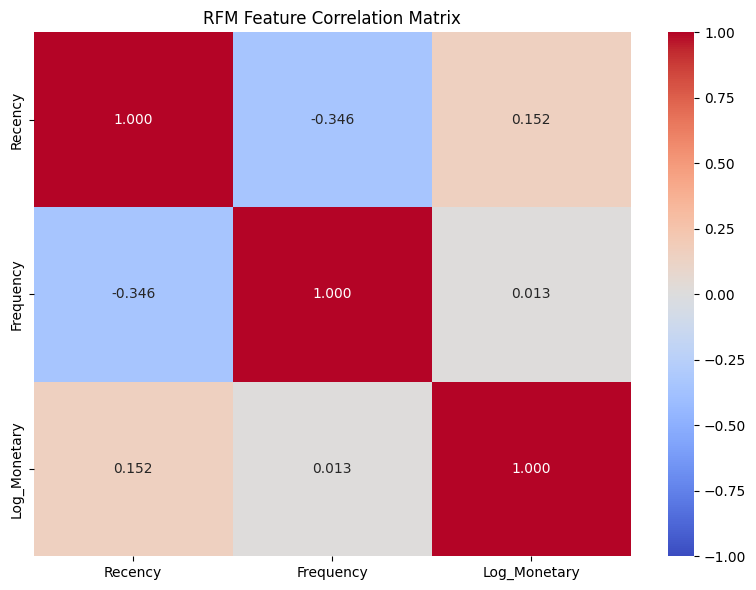

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


correlation_data = task2_data[[
    "Recency",
    "Frequency",
    "Monetary"
]].copy()


correlation_data["Log_Monetary"] = np.log1p(
    correlation_data["Monetary"]
)


rfm_correlation = correlation_data[[
    "Recency",
    "Frequency",
    "Log_Monetary"
]].corr()

print("RFM feature correlations:")
display(rfm_correlation.round(4))


plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("RFM Feature Correlation Matrix")
plt.tight_layout()
plt.show()


rfm_correlation.to_csv(
    "SP500_RFM_Correlations.csv"
)


In [ ]:



from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
import pandas as pd


rf_only = task2_data[[
    "Recency",
    "Frequency"
]].copy()


rf_scaler = StandardScaler()

X_rf = rf_scaler.fit_transform(rf_only)


k_rfm = 2

ward_rf_model = AgglomerativeClustering(
    n_clusters=k_rfm,
    linkage="ward",
    metric="euclidean"
)

ward_rf_labels = ward_rf_model.fit_predict(X_rf)


ari_rf = adjusted_rand_score(
    ward_rfm_labels,
    ward_rf_labels
)

print("Adjusted Rand Index:")
print(round(ari_rf, 4))


rf_sensitivity = task2_data.copy()

rf_sensitivity["Ward_RFM"] = ward_rfm_labels + 1
rf_sensitivity["Ward_RF_Only"] = ward_rf_labels + 1

print("\nCluster membership comparison:")
display(
    pd.crosstab(
        rf_sensitivity["Ward_RFM"],
        rf_sensitivity["Ward_RF_Only"]
    )
)


profile_columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

for method in ["Ward_RFM", "Ward_RF_Only"]:

    print(f"\nProfiles for {method}")

    profiles = rf_sensitivity.groupby(
        method
    )[profile_columns].mean()

    profiles["Monetary"] /= 1e9

    profiles = profiles.rename(columns={
        "Monetary": "Monetary_USD_Billions"
    })

    display(profiles.round(3))


rf_sensitivity.to_csv(
    "SP500_RFM_Monetary_Sensitivity.csv",
    index=False
)


Adjusted Rand Index:
0.8735

Cluster membership comparison:


Ward_RF_Only,1,2
Ward_RFM,,
1,394,10
2,3,79



Profiles for Ward_RFM


,Recency,Frequency,Monetary_USD_Billions
Ward_RFM,,,
1,12.715,3.171,37.830
2,58.305,2.098,47.159



Profiles for Ward_RF_Only


,Recency,Frequency,Monetary_USD_Billions
Ward_RF_Only,,,
1,12.302,3.209,37.807
2,56.562,2.011,46.530


In [ ]:


cluster_results.to_csv(
    "SP500_Task2_Cluster_Assignments.csv",
    index=False
)

ward_comparison.to_csv(
    "SP500_Ward_Comparison.csv",
    index=False
)

kmeans_comparison.to_csv(
    "SP500_KMeans_Comparison.csv",
    index=False
)

rfm_correlation.to_csv(
    "SP500_RFM_Correlations.csv"
)

rf_sensitivity.to_csv(
    "SP500_RFM_Monetary_Sensitivity.csv",
    index=False
)

print("Task 2 results exported successfully.")

Task 2 results exported successfully.


Shares without sector information:
0

Sector composition: Ward_Risk
Share counts:


Ward_Risk,1,2
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


Percentage of each cluster:


Ward_Risk,1,2
Sector,,
Communication Services,3.81,5.43
Consumer Discretionary,9.14,11.96
Consumer Staples,8.12,0.00
Energy,4.06,4.35
Financials,15.48,14.13
Health Care,14.21,2.17
Industrials,14.47,22.83
Information Technology,11.42,31.52
Materials,5.08,3.26


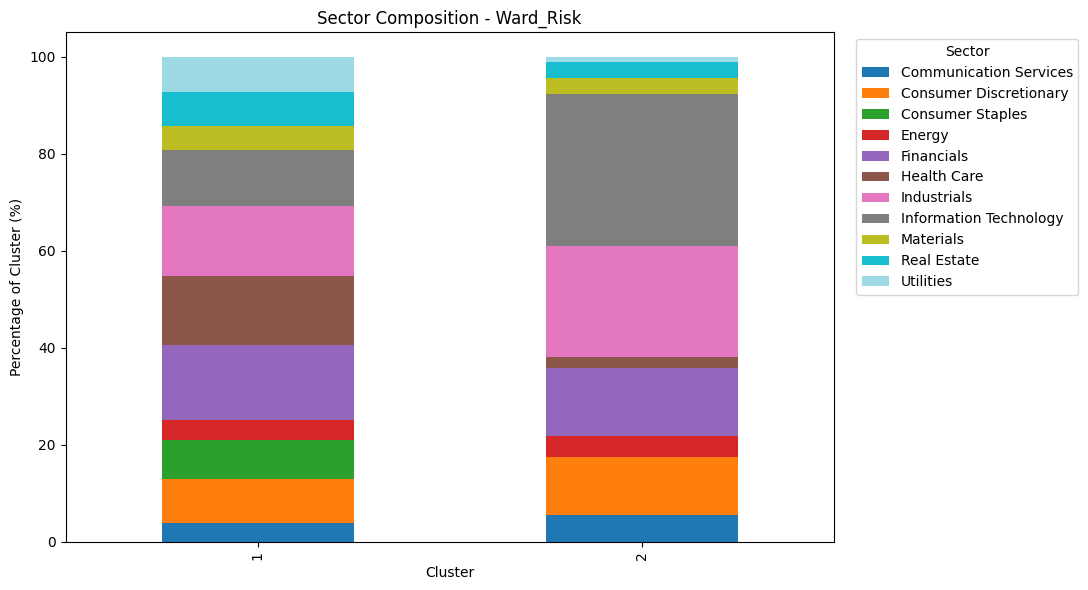


Sector composition: KMeans_Risk
Share counts:


KMeans_Risk,1,2
Sector,,
Communication Services,5,15
Consumer Discretionary,23,24
Consumer Staples,1,31
Energy,9,11
Financials,17,57
Health Care,2,56
Industrials,29,49
Information Technology,48,26
Materials,4,19


Percentage of each cluster:


KMeans_Risk,1,2
Sector,,
Communication Services,3.50,4.37
Consumer Discretionary,16.08,7.00
Consumer Staples,0.70,9.04
Energy,6.29,3.21
Financials,11.89,16.62
Health Care,1.40,16.33
Industrials,20.28,14.29
Information Technology,33.57,7.58
Materials,2.80,5.54


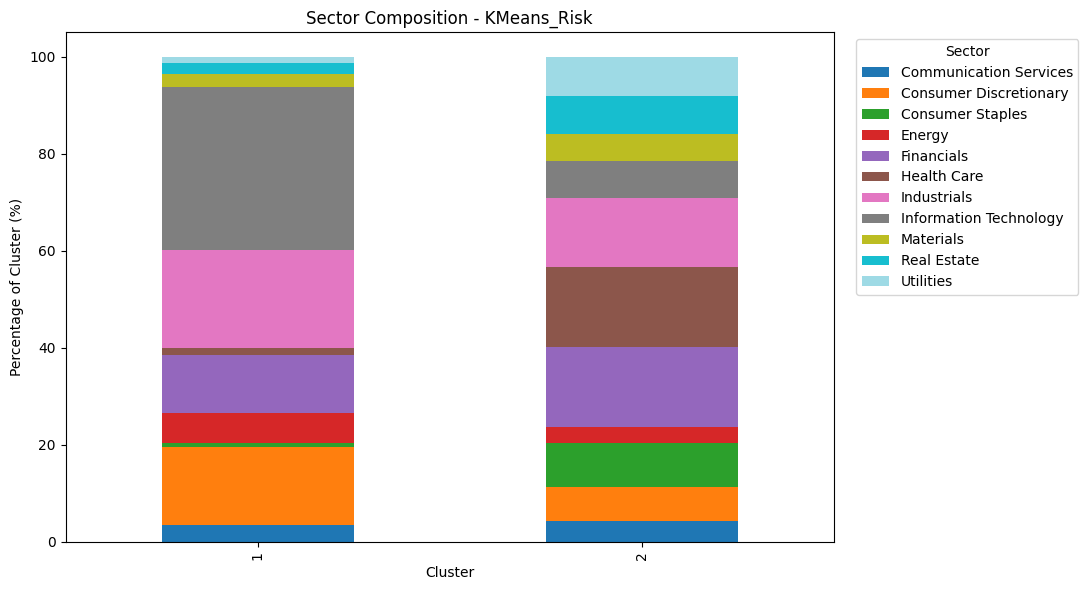


Sector composition: Ward_RFM
Share counts:


Ward_RFM,1,2
Sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


Percentage of each cluster:


Ward_RFM,1,2
Sector,,
Communication Services,3.96,4.88
Consumer Discretionary,9.41,10.98
Consumer Staples,6.19,8.54
Energy,4.46,2.44
Financials,15.84,12.20
Health Care,12.13,10.98
Industrials,17.82,7.32
Information Technology,13.86,21.95
Materials,3.71,9.76


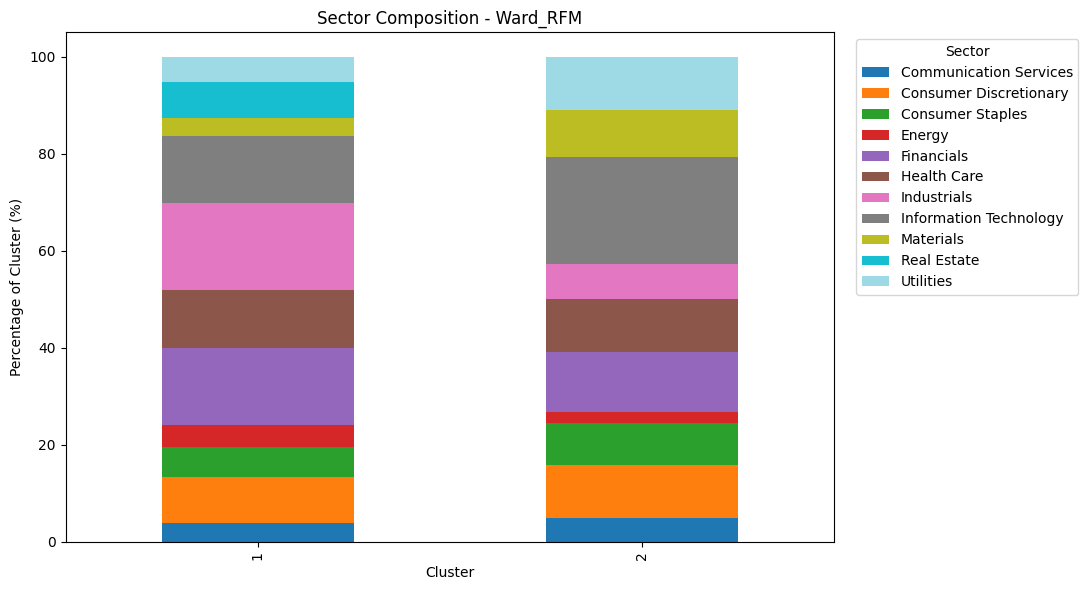


Sector composition: KMeans_RFM
Share counts:


KMeans_RFM,1,2
Sector,,
Communication Services,18,2
Consumer Discretionary,39,8
Consumer Staples,27,5
Energy,19,1
Financials,64,10
Health Care,50,8
Industrials,73,5
Information Technology,60,14
Materials,17,6


Percentage of each cluster:


KMeans_RFM,1,2
Sector,,
Communication Services,4.31,2.94
Consumer Discretionary,9.33,11.76
Consumer Staples,6.46,7.35
Energy,4.55,1.47
Financials,15.31,14.71
Health Care,11.96,11.76
Industrials,17.46,7.35
Information Technology,14.35,20.59
Materials,4.07,8.82


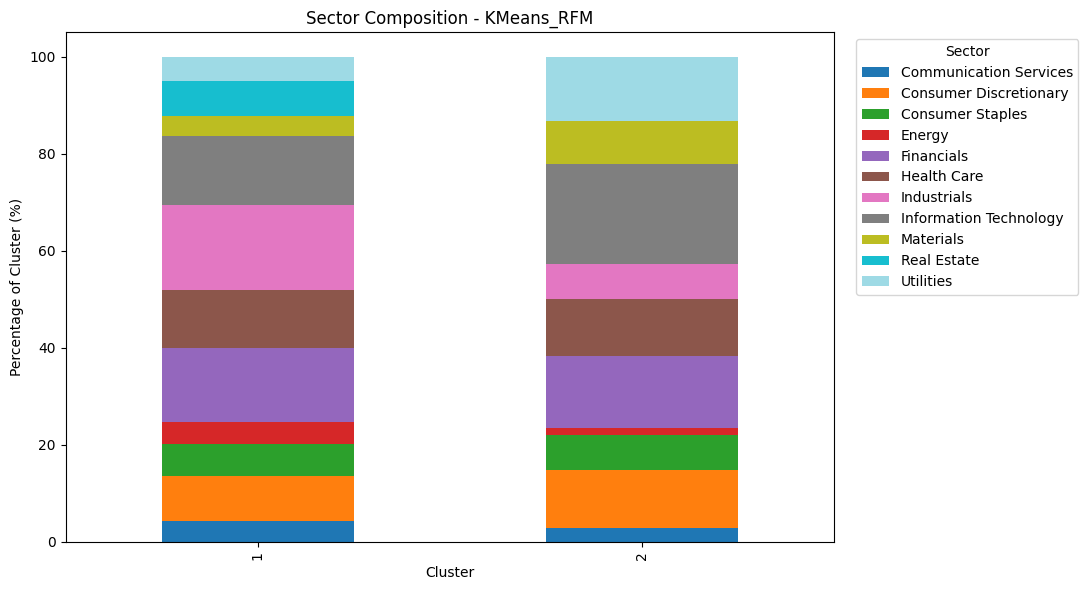

In [ ]:



import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sector_info = sp500_df[
    ["Symbol", "Security", "GICS Sector"]
].copy()


sector_info["Share"] = (
    sector_info["Symbol"]
    .str.replace(".", "-", regex=False)
)

sector_info = sector_info.rename(columns={
    "GICS Sector": "Sector",
    "Security": "Company"
})

sector_info = sector_info.drop_duplicates(
    subset="Share"
)


sector_clusters = cluster_results.merge(
    sector_info[["Share", "Company", "Sector"]],
    on="Share",
    how="left",
    validate="one_to_one"
)

print("Shares without sector information:")
print(sector_clusters["Sector"].isna().sum())


models = [
    "Ward_Risk",
    "KMeans_Risk",
    "Ward_RFM",
    "KMeans_RFM"
]

for model in models:

    print(f"\nSector composition: {model}")

    counts = pd.crosstab(
        sector_clusters["Sector"],
        sector_clusters[model]
    )

    percentages = pd.crosstab(
        sector_clusters["Sector"],
        sector_clusters[model],
        normalize="columns"
    ) * 100

    print("Share counts:")
    display(counts)

    print("Percentage of each cluster:")
    display(percentages.round(2))


    percentages.T.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 6),
        colormap="tab20"
    )

    plt.title(f"Sector Composition - {model}")
    plt.xlabel("Cluster")
    plt.ylabel("Percentage of Cluster (%)")
    plt.legend(
        title="Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()


sector_clusters.to_csv(
    "SP500_Task3_Sector_Clusters.csv",
    index=False
)


In [ ]:



models = [
    "Ward_Risk",
    "KMeans_Risk",
    "Ward_RFM",
    "KMeans_RFM"
]

profile_rows = []

for model in models:

    for cluster, group in sector_clusters.groupby(model):

        profile_rows.append({
            "Model": model,
            "Cluster": cluster,
            "Shares": len(group),
            "Mean_Return_Pct":
                group["Mean_Weekly_Return"].mean() * 100,
            "Mean_Beta":
                group["Beta"].mean(),
            "Mean_Recency_Days":
                group["Recency"].mean(),
            "Mean_Frequency":
                group["Frequency"].mean(),
            "Mean_Monetary_USD_Bn":
                group["Monetary"].mean() / 1e9
        })

task3_profiles = pd.DataFrame(profile_rows)

display(task3_profiles.round(3))

task3_profiles.to_csv(
    "SP500_Task3_Cluster_Profiles.csv",
    index=False
)


,Model,Cluster,Shares,Mean_Return_Pct,Mean_Beta,Mean_Recency_Days,Mean_Frequency,Mean_Monetary_USD_Bn
0,Ward_Risk,1,394,0.205,0.898,19.645,2.942,30.210
1,Ward_Risk,2,92,0.632,1.298,23.674,3.196,78.781
2,KMeans_Risk,1,143,0.533,1.350,22.636,3.147,81.438
3,KMeans_Risk,2,343,0.183,0.817,19.478,2.924,21.880
4,Ward_RFM,1,404,0.286,0.967,12.715,3.171,37.830
5,Ward_RFM,2,82,0.286,1.009,58.305,2.098,47.159
6,KMeans_RFM,1,418,0.283,0.972,13.423,3.187,32.691
7,KMeans_RFM,2,68,0.302,0.982,63.338,1.779,80.671
